本 notebook 是 [M01.2 数据结构与算法（科学计算取向）](../notes/02-data-structures-algorithms.qmd) 的实例讲解。用一个周期性盒子里的粒子体系，把讲义里的几种数据结构和算法各跑一遍：

1. 复杂度不是抽象概念：`list` 与 `set` 的成员查询；
2. 最小镜像约定，以及截断半径超过半个盒长时它如何出错；
3. 邻居搜索的三种实现：暴力 $O(N^2)$、从零写的 cell list、`scipy.spatial.cKDTree`，并检查三者给出完全相同的邻居对；
4. 实测 scaling：在 log–log 图上拟合斜率；
5. 排序 + 二分查找：一次排序，回答任意半径的配位数；堆：只要最近的 $k$ 个；
6. 图算法：键网络的连通分量（团簇统计、逾渗），以及用广度优先搜索求“经过每根键的最短环”。

**运行方式**：在 VS Code 中打开本文件，选择仓库 `.venv` 的 Python 内核，从上到下运行。全部单元在 CPU 上约半分钟内完成。改动代码后可用 `make nb M=01` 重新执行并保存输出。计时结果依赖机器，结论只看相对量（倍数和斜率）。

In [1]:
import bisect
import heapq
import time
from collections import Counter, deque

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib_inline.backend_inline import set_matplotlib_formats
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from scipy.spatial import cKDTree

from semiai.plotting import AQUA, BLUE, GRAY, MUTED, ORANGE, use_style

use_style()
set_matplotlib_formats("svg")
rng = np.random.default_rng(0)


def best_time(fn, repeat: int = 3) -> float:
    """重复运行 repeat 次，返回最短耗时（秒）。取最短值以减少系统噪声。"""
    times = []
    for _ in range(repeat):
        t0 = time.perf_counter()
        fn()
        times.append(time.perf_counter() - t0)
    return min(times)

## 1. 同一个问题，两种数据结构

“原子 $i$ 是否在某个集合里”（比如是否属于表面层、是否已被访问）是模拟后处理中最常见的查询。`list` 的 `in` 要逐个比较，代价 $O(n)$；`set` 是哈希表，平均 $O(1)$。下面对不同的 $n$ 各查询 1000 次。

In [2]:
rows = []
for n in (1_000, 10_000, 100_000):
    items = list(range(n))
    members = set(items)
    queries = rng.integers(0, 2 * n, size=1000).tolist()  # 约一半命中
    t_list = best_time(lambda: [q in items for q in queries])  # noqa: B023
    t_set = best_time(lambda: [q in members for q in queries])  # noqa: B023
    rows.append({"n": n, "list 耗时 / set 耗时": round(t_list / t_set)})
pd.DataFrame(rows).set_index("n")

,list 耗时 / set 耗时
n,
1000,129
10000,1153
100000,10833


读法：$n$ 每增大 10 倍，`list` 相对 `set` 的耗时比也大约增大 10 倍，这正是 $O(n)$ 与 $O(1)$ 之差。代价是 `set` 占更多内存、元素必须可哈希、不保序。在循环里反复对 `list` 做 `in`，是科研脚本中最常见的隐藏 $O(n^2)$。

## 2. 最小镜像约定

正交盒子（边长 $L$）里，两粒子的位移按[讲义的最小镜像公式](../notes/02-data-structures-algorithms.qmd#eq-minimage)折回 $[-L/2, L/2)$。下面把它与“显式枚举 27 个镜像、取最近者”的暴力做法对比。

In [3]:
def min_image(dr: np.ndarray, box: np.ndarray) -> np.ndarray:
    """正交盒子的最小镜像位移。dr: (..., 3)，box: (3,) 各方向盒长。"""
    return dr - box * np.round(dr / box)


def nearest_image_bruteforce(dr: np.ndarray, box: np.ndarray) -> np.ndarray:
    """枚举 27 个镜像平移，返回长度最短的位移。"""
    shifts = np.array([[i, j, k] for i in (-1, 0, 1) for j in (-1, 0, 1) for k in (-1, 0, 1)])
    cand = dr[:, None, :] + shifts[None, :, :] * box  # (n, 27, 3)
    best = np.argmin(np.linalg.norm(cand, axis=2), axis=1)
    return cand[np.arange(len(dr)), best]


box = np.array([10.0, 12.0, 15.0])
a = rng.uniform(0, 1, size=(5000, 3)) * box
b = rng.uniform(0, 1, size=(5000, 3)) * box
dr = b - a  # 两个都在盒内，所以每个分量在 (-L, L) 内
diff = np.abs(min_image(dr, box) - nearest_image_bruteforce(dr, box)).max()
print(f"最小镜像 vs 27 镜像暴力枚举，最大差 = {diff:.1e}")
print(
    f"最小镜像距离的最大值 = {np.linalg.norm(min_image(dr, box), axis=1).max():.3f}"
    f"，理论上限 = 半对角线 {np.linalg.norm(box / 2):.3f}"
)

最小镜像 vs 27 镜像暴力枚举，最大差 = 0.0e+00
最小镜像距离的最大值 = 10.419，理论上限 = 半对角线 10.828


两者一致。但最小镜像只给出**一个**最近镜像。如果截断半径 $r_c > L_{\min}/2$，同一对粒子可能有不止一个镜像落在截断球内，只取一个就会漏算相互作用。下面在小盒子里统计“截断球内有 2 个及以上镜像”的粒子对比例。

In [4]:
def multi_image_fraction(box: np.ndarray, r_cut: float, n_pairs: int = 20_000) -> float:
    """随机粒子对中，截断球内镜像数 ≥ 2 的比例（扫描 ±2 的镜像平移）。"""
    pts = rng.uniform(0, 1, size=(n_pairs, 3)) * box
    shifts = np.array([[i, j, k] for i in range(-2, 3) for j in range(-2, 3) for k in range(-2, 3)])
    cand = pts[:, None, :] + shifts[None, :, :] * box  # 以原点为另一粒子
    n_in = (np.linalg.norm(cand, axis=2) < r_cut).sum(axis=1)
    return float(np.mean(n_in >= 2))


cube = np.array([10.0, 10.0, 10.0])
rows = [
    {"r_c / L": f"{rc / 10:.2f}", "镜像数 ≥ 2 的比例": f"{multi_image_fraction(cube, rc):.4f}"}
    for rc in (4.0, 5.0, 5.5, 6.0, 7.0)
]
pd.DataFrame(rows).set_index("r_c / L")

,镜像数 ≥ 2 的比例
r_c / L,
0.40,0.0000
0.50,0.0000
0.55,0.0240
0.60,0.1113
0.70,0.4735


读法：$r_c \le L/2$ 时比例严格为 0；一旦超过 $L/2$，就有粒子对同时有两个镜像在截断球内，而且比例随 $r_c$ 快速增大。这就是 MD 软件在盒子太小时报错的原因。三斜（triclinic）盒子更苛刻：上面的 `round` 公式要在分数坐标里做，而且对很“歪”的晶胞，折回后的向量也不一定是最近镜像，条件要用晶胞面间距（而不是边长）的一半来判断。

## 3. 邻居搜索的三种实现

取理想气体（均匀随机）构型，数密度 $\rho = 0.8$，截断 $r_c = 1.5$（约化单位），这样每个粒子的期望邻居数就是[讲义的公式](../notes/02-data-structures-algorithms.qmd#eq-nneigh) $\rho\cdot\frac{4}{3}\pi r_c^3$。三种实现都返回 $i<j$ 的邻居对数组。

In [5]:
RHO, R_CUT = 0.8, 1.5


def make_system(n: int, rho: float = RHO, seed: int = 0) -> tuple[np.ndarray, float]:
    """立方盒子里的均匀随机构型，返回 (坐标 (n, 3), 盒长 L)。"""
    L = (n / rho) ** (1 / 3)
    return np.random.default_rng(seed).uniform(0, L, size=(n, 3)), L


def pairs_bruteforce(pos: np.ndarray, L: float, r_cut: float, chunk: int = 1000) -> np.ndarray:
    """暴力 O(N^2)：分块计算全部 i<j 的最小镜像距离，内存 O(chunk·N)。"""
    n = len(pos)
    out = []
    for start in range(0, n, chunk):
        idx = np.arange(start, min(start + chunk, n))
        d = min_image(pos[None, :, :] - pos[idx, None, :], np.full(3, L))
        r2 = np.einsum("ijk,ijk->ij", d, d)
        ii, jj = np.nonzero(r2 < r_cut**2)
        i_glob = idx[ii]
        keep = i_glob < jj
        out.append(np.column_stack([i_glob[keep], jj[keep]]))
    return np.vstack(out)


def pairs_cell_list(pos: np.ndarray, L: float, r_cut: float) -> np.ndarray:
    """cell list：把盒子分成边长 ≥ r_cut 的格子，只比较相邻的 27 个格子。

    用 dict（哈希表）把格子编号映射到粒子下标数组。
    """
    m = int(L // r_cut)  # 每个方向的格子数
    if m < 3:
        return pairs_bruteforce(pos, L, r_cut)  # 格子太少时 27 个邻居格会重复，直接退化
    cell = np.floor(pos / (L / m)).astype(int) % m
    order = np.lexsort((cell[:, 2], cell[:, 1], cell[:, 0]))
    keys = cell[order]
    cells: dict[tuple[int, int, int], np.ndarray] = {}
    boundaries = np.flatnonzero(np.any(np.diff(keys, axis=0), axis=1)) + 1
    for group in np.split(order, boundaries):
        cells[tuple(cell[group[0]])] = group
    offsets = [(i, j, k) for i in (-1, 0, 1) for j in (-1, 0, 1) for k in (-1, 0, 1)]
    box3 = np.full(3, L)
    out = []
    for (cx, cy, cz), mine in cells.items():
        for ox, oy, oz in offsets:
            other = cells.get(((cx + ox) % m, (cy + oy) % m, (cz + oz) % m))
            if other is None:
                continue
            d = min_image(pos[other][None, :, :] - pos[mine][:, None, :], box3)
            ii, jj = np.nonzero(np.einsum("ijk,ijk->ij", d, d) < r_cut**2)
            i_glob, j_glob = mine[ii], other[jj]
            keep = i_glob < j_glob  # 每对只保留一次，也去掉 i == j
            out.append(np.column_stack([i_glob[keep], j_glob[keep]]))
    return np.vstack(out)


def pairs_kdtree(pos: np.ndarray, L: float, r_cut: float) -> np.ndarray:
    """scipy 的 KD-tree；boxsize 让它直接处理周期性边界。"""
    tree = cKDTree(pos, boxsize=L)
    return tree.query_pairs(r_cut, output_type="ndarray")


def as_set(pairs: np.ndarray) -> set[tuple[int, int]]:
    return set(map(tuple, np.sort(pairs, axis=1).tolist()))


pos, L = make_system(3000)
results = {
    "暴力 O(N²)": pairs_bruteforce(pos, L, R_CUT),
    "cell list": pairs_cell_list(pos, L, R_CUT),
    "cKDTree": pairs_kdtree(pos, L, R_CUT),
}
ref = as_set(results["暴力 O(N²)"])
expected = RHO * 4 / 3 * np.pi * R_CUT**3
for name, p in results.items():
    print(
        f"{name:10s} 邻居对 {len(p):6d}  与暴力结果相同：{as_set(p) == ref}  "
        f"平均邻居数 {2 * len(p) / len(pos):.2f}"
    )
print(f"理论期望邻居数 ρ·4/3·π·r_c³ = {expected:.2f}")

暴力 O(N²)   邻居对  16892  与暴力结果相同：True  平均邻居数 11.26
cell list  邻居对  16892  与暴力结果相同：True  平均邻居数 11.26
cKDTree    邻居对  16892  与暴力结果相同：True  平均邻居数 11.26
理论期望邻居数 ρ·4/3·π·r_c³ = 11.31


读法：三种实现给出**完全相同**的邻居对集合，平均邻居数与理论值吻合（差别来自有限样本的涨落）。验证新写的邻居搜索，最可靠的办法就是与暴力结果逐对比较，而不是只比较对数。

## 4. 实测 scaling

固定密度，让 $N$ 从 500 增加到 16000，测量三种实现的耗时，在 log–log 坐标下拟合斜率。暴力法在 $N$ 较大时只测到 8000。

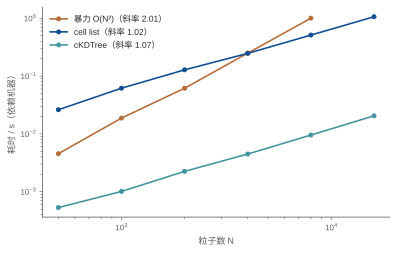

暴力 O(N²)   拟合斜率 2.01
cell list  拟合斜率 1.02
cKDTree    拟合斜率 1.07


In [6]:
sizes = [500, 1000, 2000, 4000, 8000, 16000]
timing = {"暴力 O(N²)": [], "cell list": [], "cKDTree": []}
funcs = {"暴力 O(N²)": pairs_bruteforce, "cell list": pairs_cell_list, "cKDTree": pairs_kdtree}
for n in sizes:
    pos_n, L_n = make_system(n, seed=n)
    for name, fn in funcs.items():
        if name == "暴力 O(N²)" and n > 8000:
            timing[name].append(np.nan)
            continue
        timing[name].append(best_time(lambda: fn(pos_n, L_n, R_CUT), repeat=2))  # noqa: B023

fig, ax = plt.subplots(figsize=(5.6, 3.6))
slopes = {}
for (name, ts), color in zip(timing.items(), (ORANGE, BLUE, AQUA), strict=True):
    ts = np.array(ts)
    ok = ~np.isnan(ts)
    # 只用 N >= 2000 的点拟合，避开小规模下的固定开销
    fit = ok & (np.array(sizes) >= 2000)
    slopes[name] = np.polyfit(np.log(np.array(sizes)[fit]), np.log(ts[fit]), 1)[0]
    label = f"{name}（斜率 {slopes[name]:.2f}）"
    ax.loglog(np.array(sizes)[ok], ts[ok], "o-", color=color, label=label)
ax.set_xlabel("粒子数 N")
ax.set_ylabel("耗时 / s（依赖机器）")
ax.legend(fontsize=8.5)
fig.tight_layout()
plt.show()
for name in timing:
    print(f"{name:10s} 拟合斜率 {slopes[name]:.2f}")

读法：暴力法的斜率接近 2，cell list 和 KD-tree 接近 1（KD-tree 理论上是 $O(N\log N)$ 建树 + 每个粒子 $O(\log N + k)$ 查询，在这个范围内与 1 难以区分）。绝对耗时上 `cKDTree` 是编译代码，比我们的纯 Python 循环快得多；但**斜率**与实现语言无关，它决定了体系放大 10 倍时耗时放大多少。小 $N$ 时暴力法反而可能更快：在生成这份输出的机器上，向量化的暴力法与纯 Python 循环的 cell list 在 $N$ 约几千处相交，之前暴力法占优。常数因子在小规模下占主导，这也是 MD 软件对很小的体系直接用全对循环的原因。

## 5. 排序 + 二分查找，以及堆

一次排序之后，“距离小于 $r$ 的邻居有几个”对任意 $r$ 都只需一次二分查找，代价 $O(\log n)$。这正是累积配位数 $n(r)$（RDF 的积分）的计算方式。下面以第 0 号粒子为中心。

In [7]:
pos, L = make_system(3000)
d0 = np.linalg.norm(min_image(pos - pos[0], np.full(3, L)), axis=1)[1:]  # 去掉自身
d_sorted = sorted(d0.tolist())  # O(n log n)，只做一次
for r in (1.0, 1.5, 2.0, 3.0):
    n_bisect = bisect.bisect_left(d_sorted, r)  # O(log n)
    n_scan = int(np.sum(d0 < r))  # O(n) 的直接计数，用于核对
    print(
        f"r = {r:.1f}: 二分查找 {n_bisect:4d}，直接计数 {n_scan:4d}，"
        f"理想气体期望 {RHO * 4 / 3 * np.pi * r**3:7.1f}"
    )

# 只要最近的 k 个：堆 O(n log k)，不必把 n 个距离全排序
k = 6
nearest_heap = heapq.nsmallest(k, range(len(d0)), key=d0.__getitem__)
nearest_sort = np.argsort(d0)[:k]
print(f"\n最近 {k} 个邻居（堆）：  {nearest_heap}")
print(f"最近 {k} 个邻居（全排序）：{nearest_sort.tolist()}")

r = 1.0: 二分查找    4，直接计数    4，理想气体期望     3.4
r = 1.5: 二分查找   10，直接计数   10，理想气体期望    11.3
r = 2.0: 二分查找   29，直接计数   29，理想气体期望    26.8
r = 3.0: 二分查找   89，直接计数   89，理想气体期望    90.5

最近 6 个邻居（堆）：  [1259, 2581, 2555, 706, 1628, 763]
最近 6 个邻居（全排序）：[1259, 2581, 2555, 706, 1628, 763]


读法：二分查找与直接计数完全一致。堆和全排序给出同样的 $k$ 个邻居；当 $k \ll n$ 时，`heapq.nsmallest` 的 $O(n\log k)$ 优于全排序的 $O(n\log n)$。NumPy 里对应的工具是 `np.searchsorted`（二分查找）和 `np.argpartition`（选出前 $k$ 个，平均 $O(n)$）。堆的另一个典型用途是事件驱动模拟：按发生时间取出下一个碰撞或反应事件。

## 6. 图算法：团簇、逾渗与最短环

构造一个“带空位的简单立方晶格”：$20^3$ 个格点，每个格点以概率 $p$ 被占据，坐标加小的随机扰动。相距小于 1.2 个晶格常数的占据格点之间连一根键，得到键网络（图）。先用连通分量统计团簇。

In [8]:
def lattice_network(p: float, n_side: int = 20, seed: int = 0) -> tuple[np.ndarray, np.ndarray]:
    """带空位、带扰动的简单立方晶格（非周期）。返回 (坐标, 键的端点对 (n_bond, 2))。"""
    g = np.random.default_rng(seed)
    grid = np.stack(np.meshgrid(*[np.arange(n_side)] * 3, indexing="ij"), -1).reshape(-1, 3)
    occupied = grid[g.random(len(grid)) < p].astype(float)
    # 扰动要足够小：键长 1 ± 扰动不能超过截断 1.2，面对角线 √2 ± 扰动也不能缩到 1.2 以内
    pts = occupied + 0.04 * g.normal(size=occupied.shape)
    bonds = cKDTree(pts).query_pairs(1.2, output_type="ndarray")
    return pts, bonds


def clusters(n_nodes: int, bonds: np.ndarray) -> np.ndarray:
    """连通分量标签：用稀疏邻接矩阵 + scipy.sparse.csgraph。"""
    adj = coo_matrix((np.ones(len(bonds)), (bonds[:, 0], bonds[:, 1])), shape=(n_nodes, n_nodes))
    _, labels = connected_components(adj, directed=False)
    return labels


rows = []
ps = np.round(np.arange(0.15, 0.61, 0.05), 2)
largest = []
for p in ps:
    pts, bonds = lattice_network(p)
    labels = clusters(len(pts), bonds)
    sizes_c = np.bincount(labels)
    largest.append(sizes_c.max() / len(pts))
    rows.append(
        {
            "p": p,
            "原子数": len(pts),
            "团簇数": len(sizes_c),
            "最大团簇占比": f"{sizes_c.max() / len(pts):.3f}",
        }
    )
pd.DataFrame(rows).set_index("p")

,原子数,团簇数,最大团簇占比
p,,,
0.15,1244,715,0.010
0.20,1653,735,0.019
0.25,2043,674,0.036
0.30,2416,550,0.091
0.35,2810,389,0.468
0.40,3221,253,0.822
0.45,3644,160,0.911
0.50,4009,113,0.958
0.55,4391,67,0.978


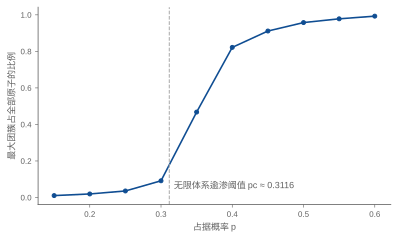

In [9]:
fig, ax = plt.subplots(figsize=(5.6, 3.4))
ax.plot(ps, largest, "o-", color=BLUE)
ax.axvline(0.3116, color=GRAY, ls="--", lw=1)
ax.text(0.318, 0.05, "无限体系逾渗阈值 pc ≈ 0.3116", color=MUTED, fontsize=9)
ax.set_xlabel("占据概率 p")
ax.set_ylabel("最大团簇占全部原子的比例")
fig.tight_layout()
plt.show()

读法：最大团簇的占比在 $p = 0.30$ 到 $0.40$ 之间从不到 0.1 跃升到 0.8 以上，对应简单立方晶格的格点逾渗阈值 $p_c \approx 0.3116$。有限尺寸（$20^3$）让转变被抹平成一段斜坡。同样的“建图 → 连通分量”流程可以直接用于 MD 构型：团簇分析、晶核识别（只把满足局部序参数的原子连键）、导电通路是否贯通。

接下来看环。对每根键 $(i, j)$，暂时删掉它，用广度优先搜索（BFS）找 $i$ 到 $j$ 的最短路径，路径长度加 1 就是“经过这根键的最短环”的大小。BFS 在无权图上的复杂度是 $O(V+E)$，这里限制搜索深度，代价更小。

In [10]:
def adjacency_lists(n_nodes: int, bonds: np.ndarray) -> list[list[int]]:
    adj: list[list[int]] = [[] for _ in range(n_nodes)]
    for i, j in bonds.tolist():
        adj[i].append(j)
        adj[j].append(i)
    return adj


def shortest_ring_through(adj: list[list[int]], i: int, j: int, max_size: int = 10) -> int | None:
    """删掉键 (i, j) 后 BFS 求 i→j 的最短路径，返回环大小；超过 max_size 返回 None。"""
    dist = {i: 0}
    queue = deque([i])
    while queue:
        u = queue.popleft()
        if dist[u] + 1 >= max_size:
            break
        for v in adj[u]:
            if (u, v) in ((i, j), (j, i)) or v in dist:
                continue
            dist[v] = dist[u] + 1
            if v == j:
                return dist[v] + 1
            queue.append(v)
    return None


ring_rows = []
for p in (1.0, 0.85, 0.7):
    pts, bonds = lattice_network(p, n_side=12, seed=1)
    adj = adjacency_lists(len(pts), bonds)
    counts = Counter(shortest_ring_through(adj, i, j) for i, j in bonds.tolist())
    total = sum(counts.values())
    row = {"p": p, "键数": total}
    for size in sorted(s for s in counts if s is not None):
        row[f"最短环 = {size}"] = f"{counts[size] / total:.3f}"
    row["无 ≤10 元环"] = f"{counts.get(None, 0) / total:.3f}"
    ring_rows.append(row)
ring_table = pd.DataFrame(ring_rows).set_index("p").fillna("0")
ring_cols = sorted(
    (c for c in ring_table.columns if c.startswith("最短环")), key=lambda c: int(c.split("= ")[1])
)
ring_table[["键数", *ring_cols, "无 ≤10 元环"]]

,键数,最短环 = 3,最短环 = 4,最短环 = 6,最短环 = 8,最短环 = 10,无 ≤10 元环
p,,,,,,,
1.00,4751,0,1.000,0,0,0,0.000
0.85,3431,0,0.988,0.006,0.005,0,0.001
0.70,2352,0.002,0.920,0.021,0.034,0.012,0.010


读法：完整的简单立方晶格里每根键都在一个 4 元环（一个立方面）上，所以比例为 1；引入空位后，部分键的最短环变成 6、8、10 元环，还有一部分键不在任何 10 元以内的环上（比如悬挂键）。

$p = 0.7$ 那一行出现了少量 3 元环。简单立方晶格的近邻图是二分图，只有偶数元环；3 元环说明有一根“键”其实是面对角线，扰动恰好把它的长度压到了截断 1.2 以内。这是用单一截断定义成键的固有问题：截断取在两个配位壳层之间的空隙里还不够，空隙两侧的分布尾部都会造成错误的键，进而改变环统计。处理真实 MD 构型时，截断通常取在 RDF 第一个极小值处，并检查结果对截断的敏感度。

这只是“每根键的最短环”统计，不是完整的环统计：非晶网络文献中常用的最短路径环（Franzblau 的 SP rings）、King 环、primitive rings 定义各不相同，计数结果也不同。要和文献比较，必须先对齐环的定义。

## 小结

- 数据结构的选择直接改变复杂度：`list` 的 `in` 是 $O(n)$，`set` 是 $O(1)$。
- 最小镜像在 $r_c \le L/2$ 时正确；超过之后同一对粒子可能有多个镜像在截断球内。
- cell list 与 KD-tree 在固定密度下都把邻居搜索从 $O(N^2)$ 降到约 $O(N)$；验证新实现时要与暴力结果逐对比较。
- 一次排序 + 多次二分查找，回答任意半径的配位数；只要前 $k$ 个时用堆或 `argpartition`。
- 键网络就是图：连通分量给出团簇和逾渗，BFS 给出最短路径和最短环。

可以尝试：把第 3 节的 `R_CUT` 加大到 $L/3$ 以上，看 `pairs_cell_list` 何时退化为暴力法；把第 4 节的密度改为 0.2 或 1.2，斜率是否改变、绝对耗时如何变化；在第 6 节用 `scipy.sparse.csgraph.shortest_path` 计算最大团簇的直径（最长的最短路径）。